## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [1]:
!pip install scikit-misc


In [2]:
!pip install scanpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 30.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 66.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.2 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [3]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  17.8M      0 --:--:-- --:--:-- --:--:-- 17.8M


In [4]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [5]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [6]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [7]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [8]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [9]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [10]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData?

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [11]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [12]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

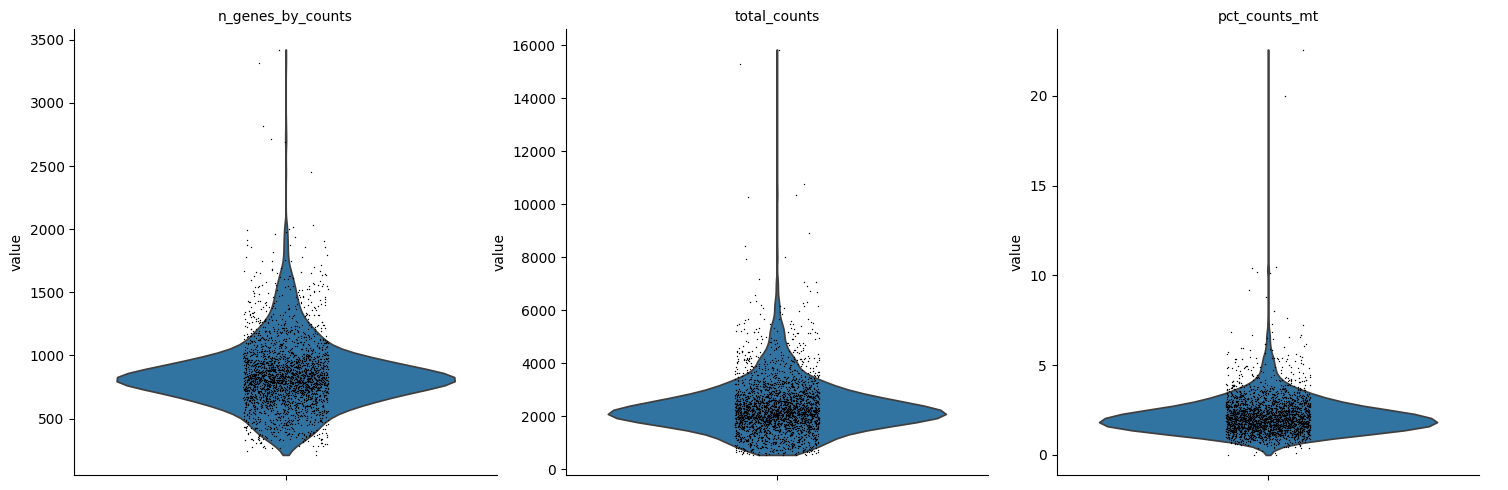

In [13]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [14]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [15]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [16]:
adata.layers["counts"] = adata.X.copy()

In [17]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

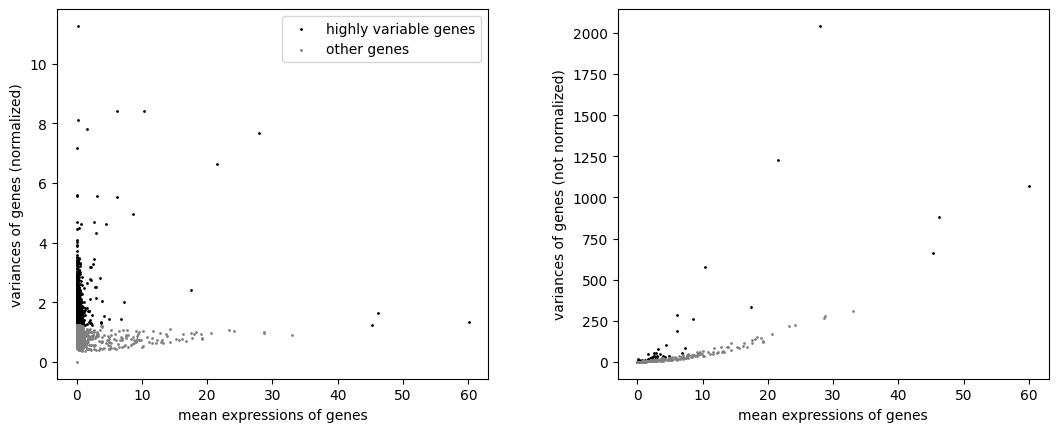

In [18]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [19]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

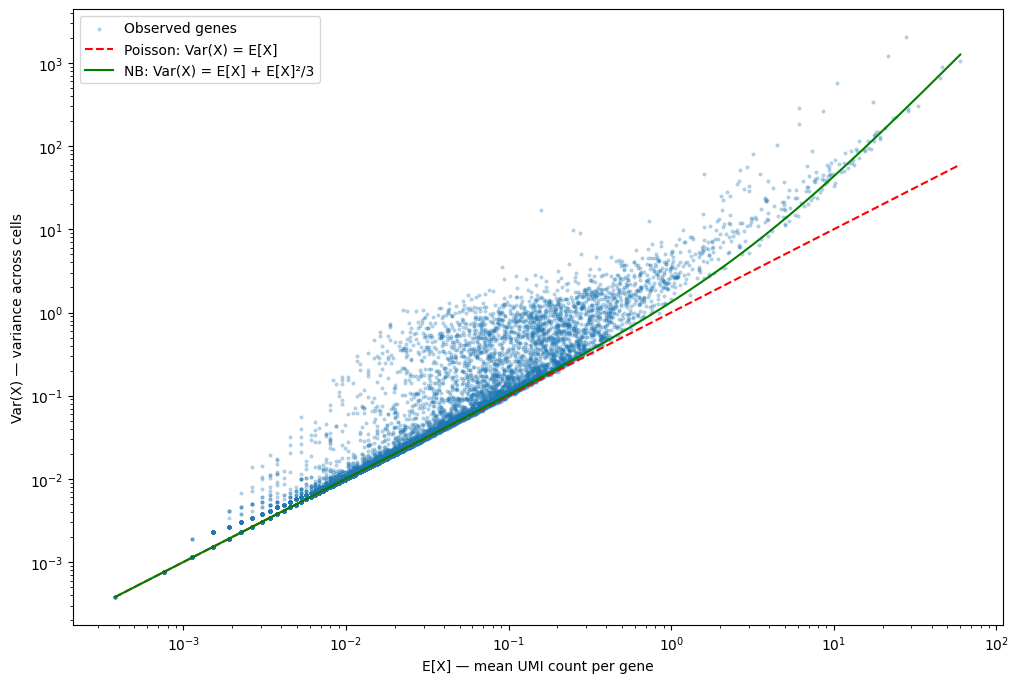

In [20]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [21]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [22]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

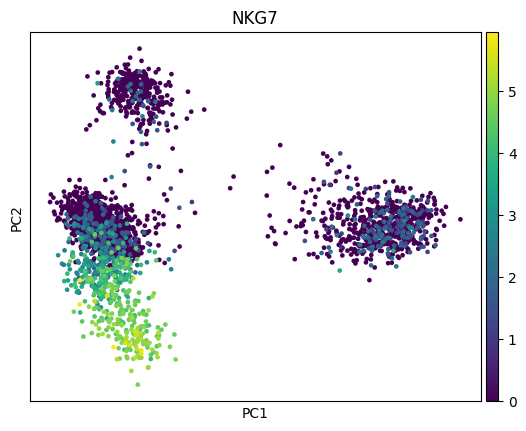

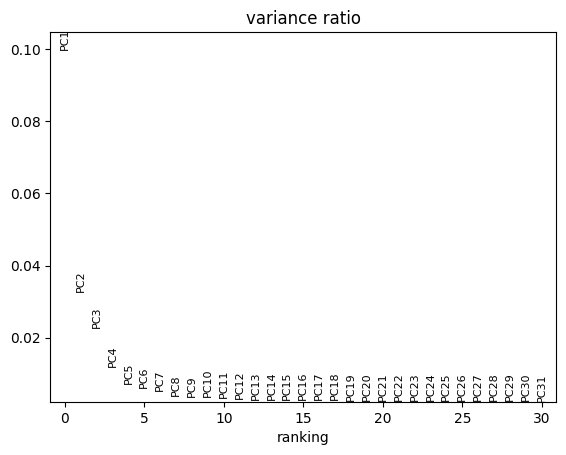

In [23]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [24]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили.

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [25]:
from pathlib import Path
import urllib.request
import tarfile
import scanpy as sc
import matplotlib.pyplot as plt

OUT = Path("results_sc")
OUT.mkdir(exist_ok=True)

archive = Path("data/pbmc3k.tar.gz")
folder = Path("data/filtered_gene_bc_matrices/hg19")

if not (folder / "matrix.mtx").exists():
    archive.parent.mkdir(exist_ok=True)
    if not archive.exists():
        url = "https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz"
        urllib.request.urlretrieve(url, archive)
    with tarfile.open(archive, "r:gz") as files:
        files.extractall("data")

raw = sc.read_10x_mtx(folder, var_names="gene_symbols")
raw.var_names_make_unique()

raw.var["mt"] = raw.var_names.str.startswith("MT-")
raw.var["ribo"] = raw.var_names.str.startswith(("RPL", "RPS"))
raw.var["hb"] = raw.var_names.str.match(r"^HB[ABDEGMQZ][0-9]*$")
raw.var["malat1"] = raw.var_names.str.upper() == "MALAT1"

sc.pp.calculate_qc_metrics(
    raw, qc_vars=["mt", "ribo", "hb", "malat1"],
    percent_top=None, inplace=True
)

filtered = raw.copy()
sc.pp.filter_cells(filtered, min_genes=200)
sc.pp.filter_genes(filtered, min_cells=3)
filtered = filtered[
    (filtered.obs["n_genes_by_counts"] < 2500) &
    (filtered.obs["pct_counts_mt"] < 5)
].copy()

print("Исходная матрица:", raw.shape)
print("После QC:", filtered.shape)

Исходная матрица: (2700, 32738)
После QC: (2638, 13714)


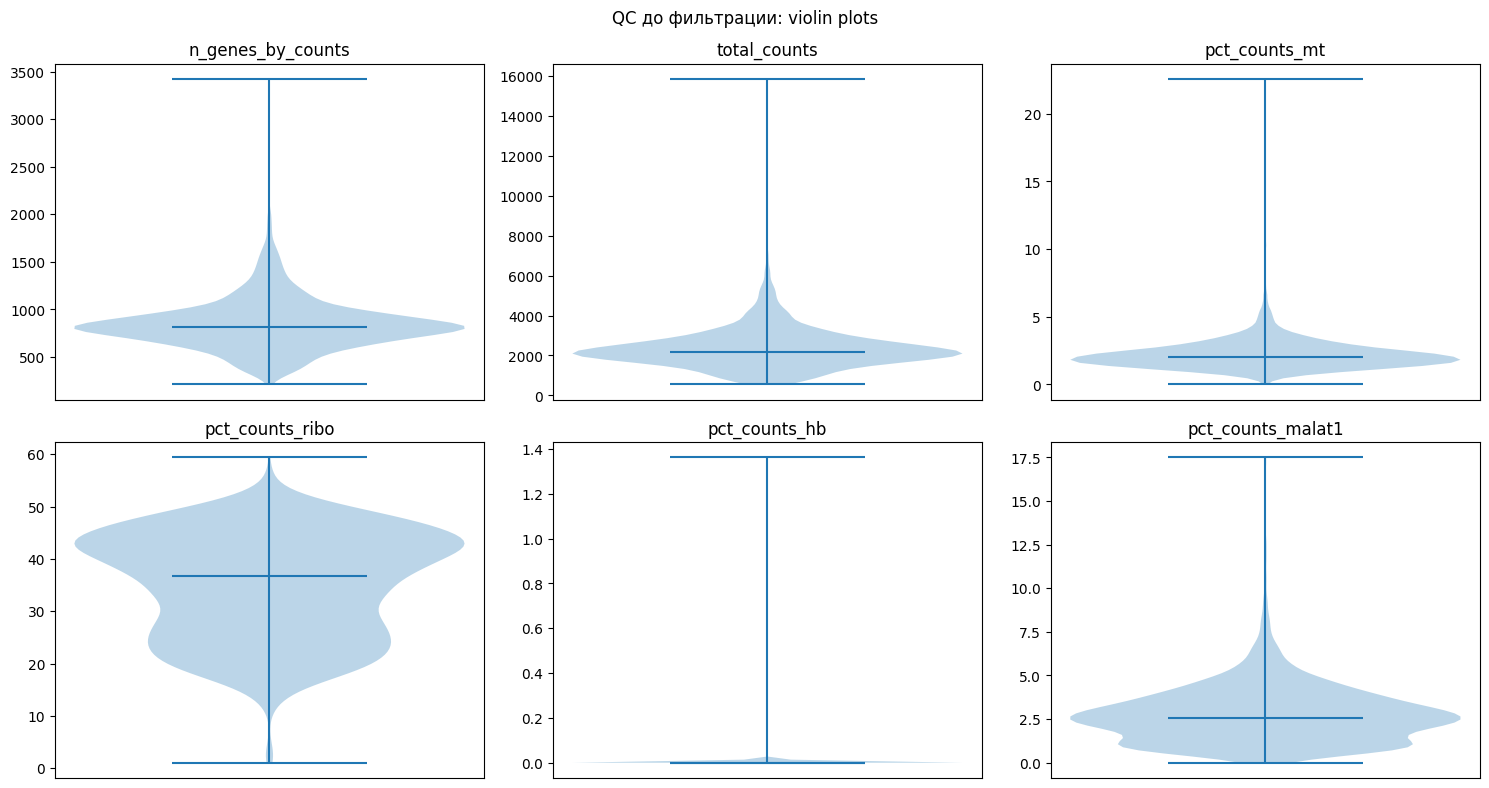

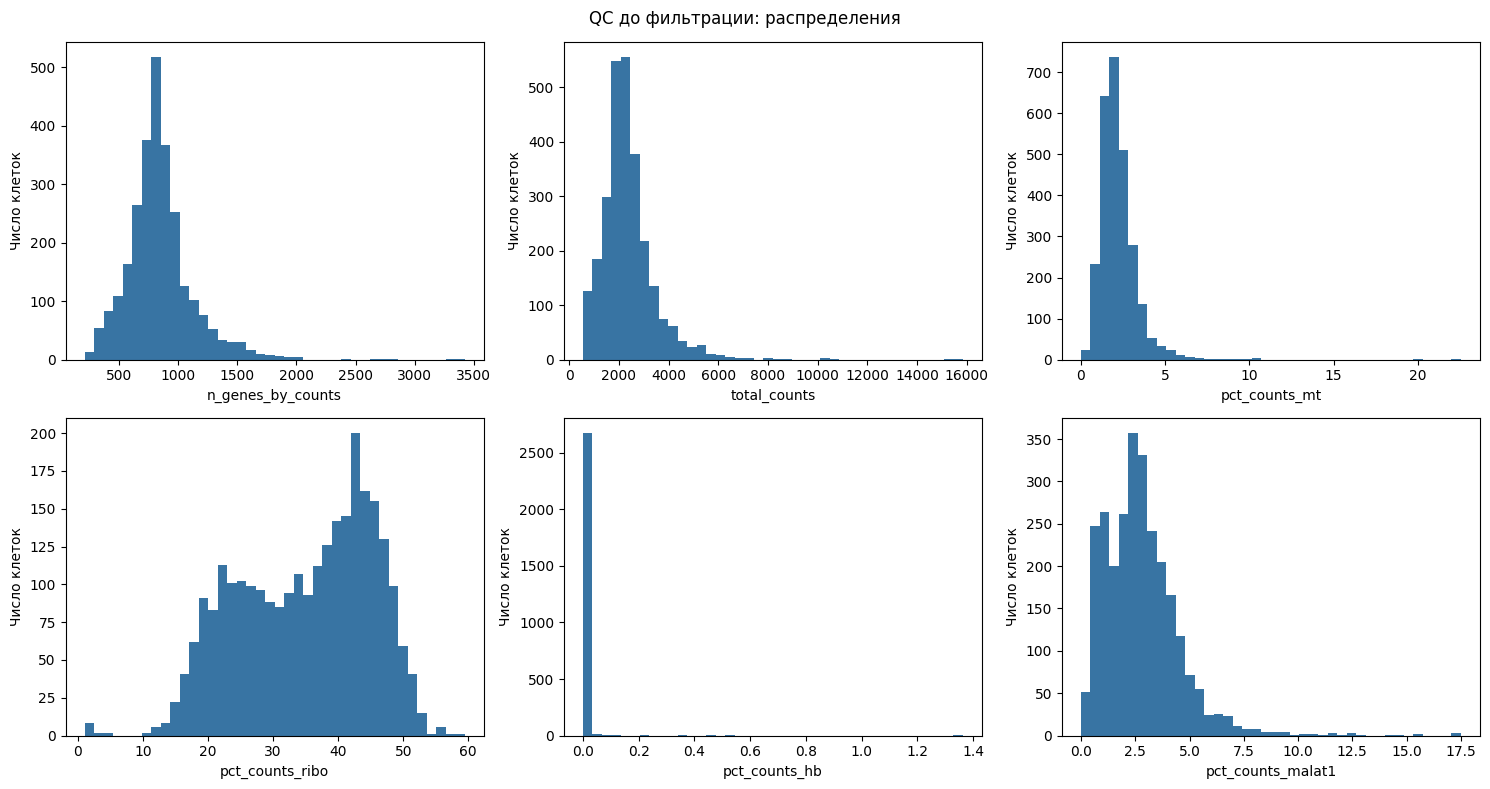

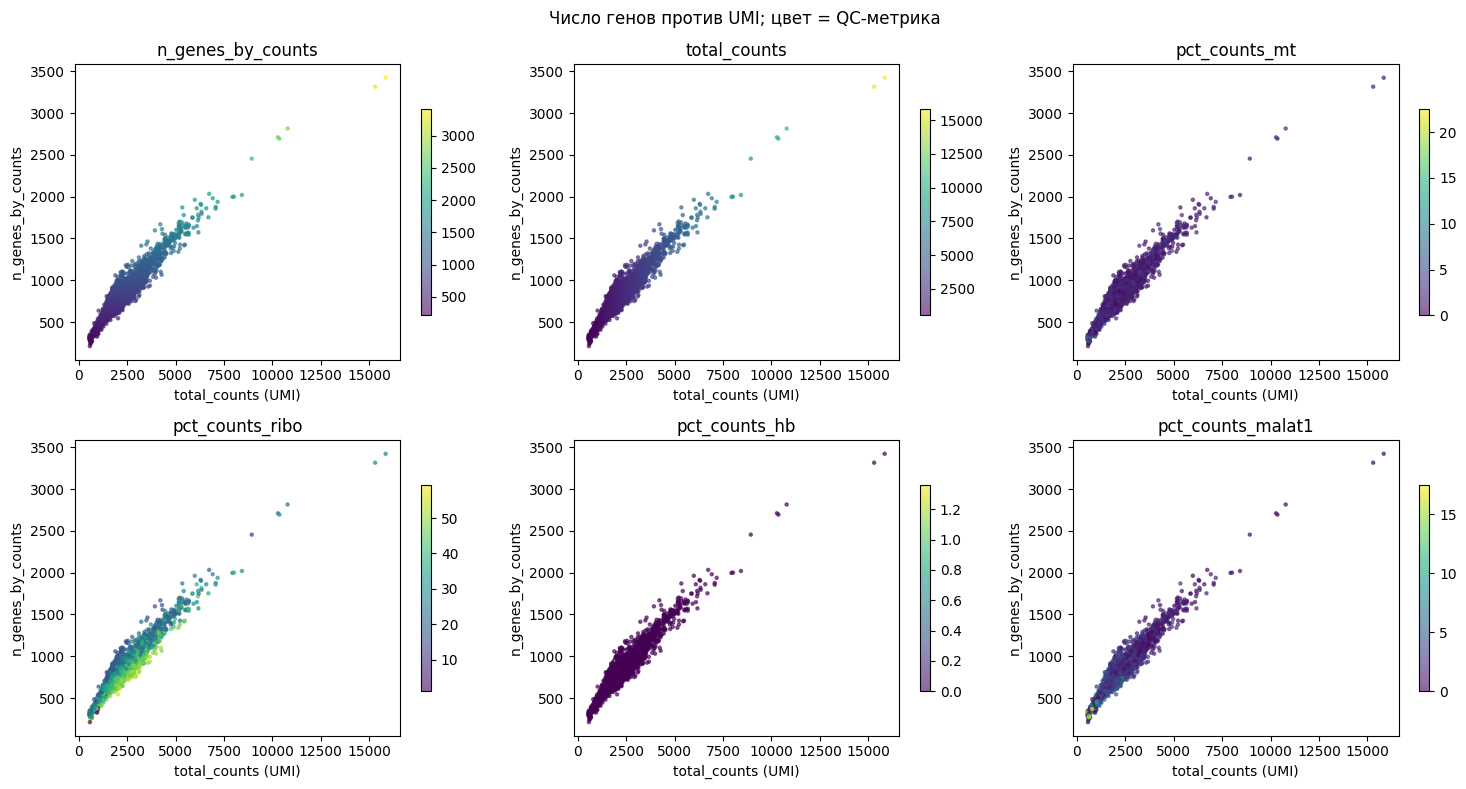

Доля оставшихся клеток: 97.7%


In [26]:
METRICS = ["n_genes_by_counts", "total_counts", "pct_counts_mt",
           "pct_counts_ribo", "pct_counts_hb", "pct_counts_malat1"]

def finish_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=180, bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.ravel(), METRICS):
    ax.violinplot(raw.obs[metric].to_numpy(), showmedians=True)
    ax.set_title(metric)
    ax.set_xticks([])
fig.suptitle("QC до фильтрации: violin plots")
finish_figure("task1_violin.png")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.ravel(), METRICS):
    ax.hist(raw.obs[metric], bins=40, color="#3874a3")
    ax.set(xlabel=metric, ylabel="Число клеток")
fig.suptitle("QC до фильтрации: распределения")
finish_figure("task1_hist.png")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.ravel(), METRICS):
    im = ax.scatter(raw.obs["total_counts"], raw.obs["n_genes_by_counts"],
                    c=raw.obs[metric], cmap="viridis", s=5, alpha=.6, rasterized=True)
    ax.set(xlabel="total_counts (UMI)", ylabel="n_genes_by_counts", title=metric)
    fig.colorbar(im, ax=ax, shrink=.7)
fig.suptitle("Число генов против UMI; цвет = QC-метрика")
finish_figure("task1_scatter.png")

print("Доля оставшихся клеток: {:.1f}%".format(100 * filtered.n_obs / raw.n_obs))

In [27]:
import numpy as np
import pandas as pd
from scipy import sparse

raw.layers["counts"] = raw.X.copy()
filtered.layers["counts"] = filtered.X.copy()

norm = filtered.copy()
sc.pp.normalize_total(norm, target_sum=1e4)
sc.pp.log1p(norm)

print("Нормализованная матрица готова:", norm.shape)

Нормализованная матрица готова: (2638, 13714)


In [28]:
MARKERS = [g for g in ("CD3D", "MS4A1", "NKG7", "LST1") if g in norm.var_names]
print("Маркеры в матрице:", MARKERS)

def pca_copy(base, mask=None):
    obj = base.copy()
    if mask is not None:
        obj.var["chosen_hvg"] = np.asarray(mask, dtype=bool)
        sc.pp.pca(obj, n_comps=30, mask_var="chosen_hvg", svd_solver="arpack", random_state=0)
    else:
        sc.pp.pca(obj, n_comps=30, mask_var=None, svd_solver="arpack", random_state=0)
    return obj

def gene_values(obj, gene):
    values = obj[:, gene].X
    return values.toarray().ravel() if sparse.issparse(values) else np.asarray(values).ravel()

def plot_marker_comparison(objects, labels, filename):
    fig, axes = plt.subplots(len(objects), len(MARKERS),
                             figsize=(4 * len(MARKERS), 3.4 * len(objects)), squeeze=False)
    for row, (obj, label) in enumerate(zip(objects, labels)):
        for col, gene in enumerate(MARKERS):
            ax = axes[row, col]
            vals = gene_values(obj, gene)
            im = ax.scatter(obj.obsm["X_pca"][:, 0], obj.obsm["X_pca"][:, 1],
                            c=vals, s=5, cmap="viridis", rasterized=True)
            ax.set(xlabel="PC1", ylabel="PC2", title=f"{label}: {gene}")
            fig.colorbar(im, ax=ax, shrink=.7)
    finish_figure(filename)

Маркеры в матрице: ['CD3D', 'MS4A1', 'NKG7', 'LST1']


После проверки качества осталось 97,7% клеток, а 2,3% исключили. У большинства клеток обнаружено примерно 700–1000 генов и 1500–3000 UMI, доля митохондриальных UMI обычно составляет около 1–3%. Подозрительно выглядят отдельные клетки, у которых эта доля превышает 5% и доходит примерно до 22%. Ещё есть редкие клетки с 2500–3400 генами и 10–16 тысячами UMI: возможно, в одну каплю попали две клетки. Доля рибосомных генов у клеток различается примерно от 10% до 50%. Сама по себе высокая доля не означает плохое качество: она может быть особенностью клеток, поэтому её нужно оценивать вместе с остальными показателями.

О низком качестве могут говорить малая численность обнаруженных генов и UMI, а также высокая доля митохондриальных транскриптов. При этом высокую долю отдельной группы генов нельзя автоматически считать признаком плохой клетки. Например, на наших графиках доля рибосомных генов у разных клеток заметно различается; это может отражать особенности их типа или состояния. Поэтому показатели нужно рассматривать вместе, а не оценивать клетку по одному числу.

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`.

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


seurat_v3 HVG: 2000
seurat HVG: 2000
pearson HVG: 2000
seurat_v3 ∩ seurat: 1505
seurat_v3 ∩ pearson: 1402
seurat ∩ pearson: 1291
Все три: 1145


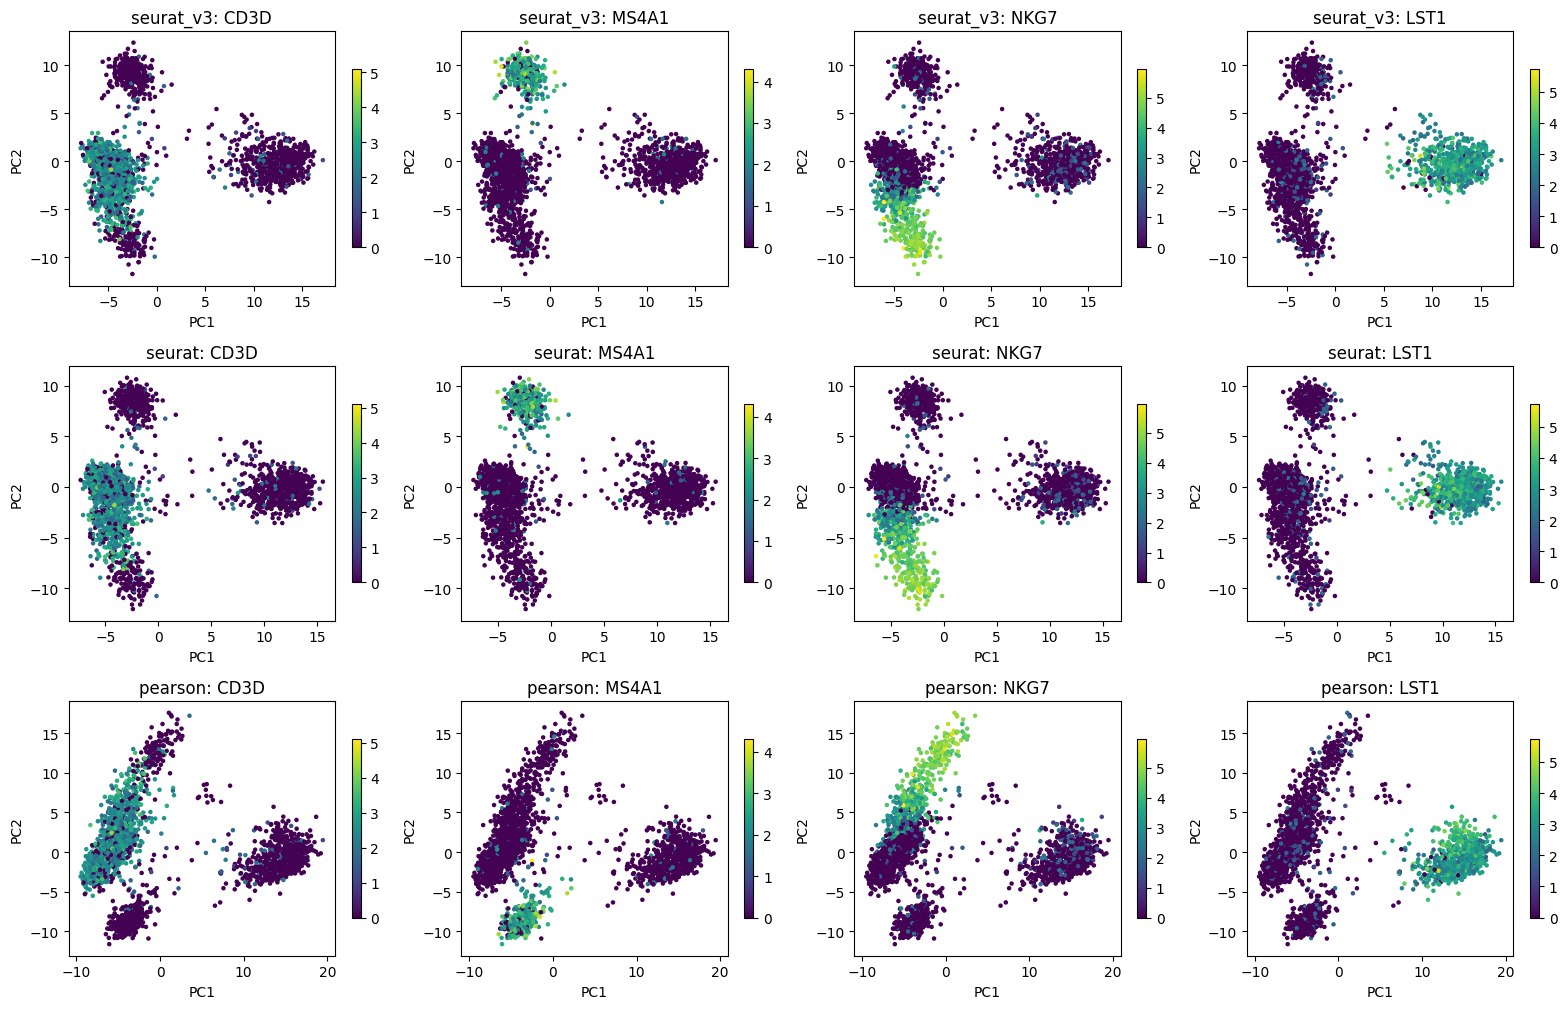

In [29]:
v3 = sc.pp.highly_variable_genes(filtered, layer="counts", flavor="seurat_v3",
                                  n_top_genes=2000, inplace=False)
seurat = sc.pp.highly_variable_genes(norm, flavor="seurat",
                                      n_top_genes=2000, inplace=False)
pearson = sc.experimental.pp.highly_variable_genes(
    filtered, layer="counts", flavor="pearson_residuals", n_top_genes=2000, inplace=False
)
hvg = {"seurat_v3": v3["highly_variable"].reindex(norm.var_names).fillna(False).to_numpy(),
       "seurat": seurat["highly_variable"].reindex(norm.var_names).fillna(False).to_numpy(),
       "pearson": pearson["highly_variable"].reindex(norm.var_names).fillna(False).to_numpy()}
pcas = {name: pca_copy(norm, mask) for name, mask in hvg.items()}
for name, mask in hvg.items():
    print(name, "HVG:", int(mask.sum()))
print("seurat_v3 ∩ seurat:", int((hvg["seurat_v3"] & hvg["seurat"]).sum()))
print("seurat_v3 ∩ pearson:", int((hvg["seurat_v3"] & hvg["pearson"]).sum()))
print("seurat ∩ pearson:", int((hvg["seurat"] & hvg["pearson"]).sum()))
print("Все три:", int(np.logical_and.reduce(list(hvg.values())).sum()))
plot_marker_comparison(list(pcas.values()), list(pcas), "task2_hvg_pca_markers.png")

In [30]:
print((hvg["seurat_v3"] & hvg["seurat"]).sum())

1505


Методы seurat_v3 и seurat дают очень похожее расположение клеток на PCA.

одновременно попали 1505 генов из 2000 (примерно 75%). Значит, методы выбрали во многом похожие гены, хотя результаты не полностью совпали.

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


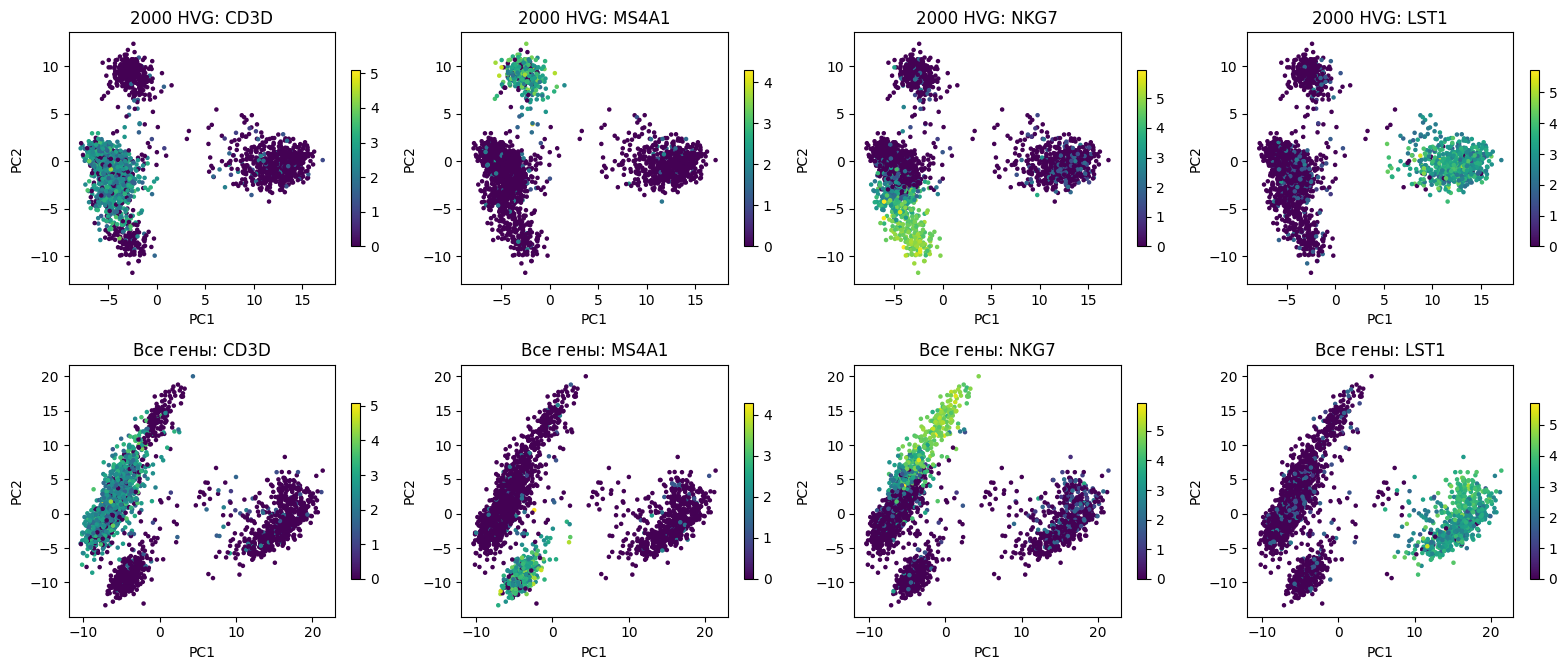

2000 HVG PC1 9.98%, PC2 3.28%, PC1–10 19.66%
Все гены PC1 4.58%, PC2 1.60%, PC1–10 10.03%


In [31]:
pca_all = pca_copy(norm, mask=None)
plot_marker_comparison([pcas["seurat_v3"], pca_all], ["2000 HVG", "Все гены"],
                       "task3_hvg_vs_all.png")
for label, obj in [("2000 HVG", pcas["seurat_v3"]), ("Все гены", pca_all)]:
    ratio = obj.uns["pca"]["variance_ratio"]
    print(label, "PC1 {:.2%}, PC2 {:.2%}, PC1–10 {:.2%}".format(
        ratio[0], ratio[1], ratio[:10].sum()))

Когда я построила PCA по всем генам, группы клеток немного изменили форму и положение, но остались различимыми. Например, клетки с высокой экспрессией LST1 по-прежнему образуют отдельную группу.
При использовании 2000 HVG первая компонента объясняет 9,98% дисперсии, вторая 3,28%, а первые десять вместе 19,66%. При использовании всех генов значения ниже: 4,58%, 1,60% и 10,03%. Большее число генов не обязательно помогает анализу, потому что часть генов мало различается между клетками и добавляет шум.

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


In [32]:
counts = filtered.layers["counts"]
mean_umi = np.asarray(counts.mean(axis=0)).ravel()
mean_sq = np.asarray(counts.multiply(counts).mean(axis=0)).ravel() if sparse.issparse(counts)           else np.asarray(np.square(counts).mean(axis=0)).ravel()
variance = np.maximum(0, mean_sq - mean_umi**2)
gene_stats = pd.DataFrame({"gene": filtered.var_names, "mean_umi": mean_umi,
                           "variance_umi": variance, "hvg_v3": hvg["seurat_v3"]})
top_hvg = gene_stats[gene_stats.hvg_v3].nlargest(50, "mean_umi")
top_other = gene_stats[~gene_stats.hvg_v3].nlargest(50, "mean_umi")
top_hvg.to_csv(OUT / "task4_top50_hvg.csv", index=False)
top_other.to_csv(OUT / "task4_top50_other.csv", index=False)
print("HVG, первые 10:")
display(top_hvg.head(10))
print("Не HVG, первые 10:")
display(top_other.head(10))
print("Медианы внутри двух top-50:")
display(pd.DataFrame({"HVG": top_hvg[["mean_umi", "variance_umi"]].median(),
                      "не HVG": top_other[["mean_umi", "variance_umi"]].median()}))

HVG, первые 10:


,gene,mean_umi,variance_umi,hvg_v3
7854,MALAT1,60.036732,1066.570312,True
5540,TMSB4X,46.140289,883.349854,True
9781,B2M,45.289223,659.148682,True
12943,FTL,27.999430,2041.886475,True
7754,FTH1,21.535463,1224.520508,True
4926,ACTB,17.458569,334.396576,True
8681,LYZ,10.408192,575.139343,True
4025,CD74,8.579643,261.793152,True
912,S100A4,7.343126,86.244446,True
13699,MT-CO2,6.888643,56.957253,True


Не HVG, первые 10:


,gene,mean_umi,variance_umi,hvg_v3
5915,RPL10,33.017464,307.453003,False
10709,RPL13,28.774101,280.543518,False
12956,RPL13A,28.644434,264.611633,False
10129,RPS2,24.092089,222.750671,False
6461,RPS6,23.292944,217.958923,False
4436,RPS18,20.609489,166.668060,False
227,RPL11,19.285789,128.377533,False
2390,RPL32,19.239534,122.027008,False
8004,RPS3,19.013590,146.748871,False
11118,RPL19,18.272491,149.700043,False


Медианы внутри двух top-50:


,HVG,не HVG
mean_umi,2.627000,12.928123
variance_umi,29.460018,67.716034


нет HVG не обязательно являются наиболее экспрессируемыми генами,  при их выборе учитывается не только средняя экспрессия, но и то, насколько сильно она меняется между клетками. Поэтому ген может иметь высокую экспрессию, но не попасть в HVG, если он работает примерно одинаково во всех клетках.
среди высокоэкспрессируемых не хвг у меня оказалось много рибосомальных генов, например RPL10, RPL13, RPS2, RPS6. У топ 50 не-HVG медиана средней экспрессии выше чем у хвг (12,93 при 2,63 соответсвенно). Среди наиболее экспрессируемых также встречаются митохондриальные гены, гены общего клеточного функционирования (ACTB и MALAT1), и иммунные гены B2M, LYZ и CD74

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

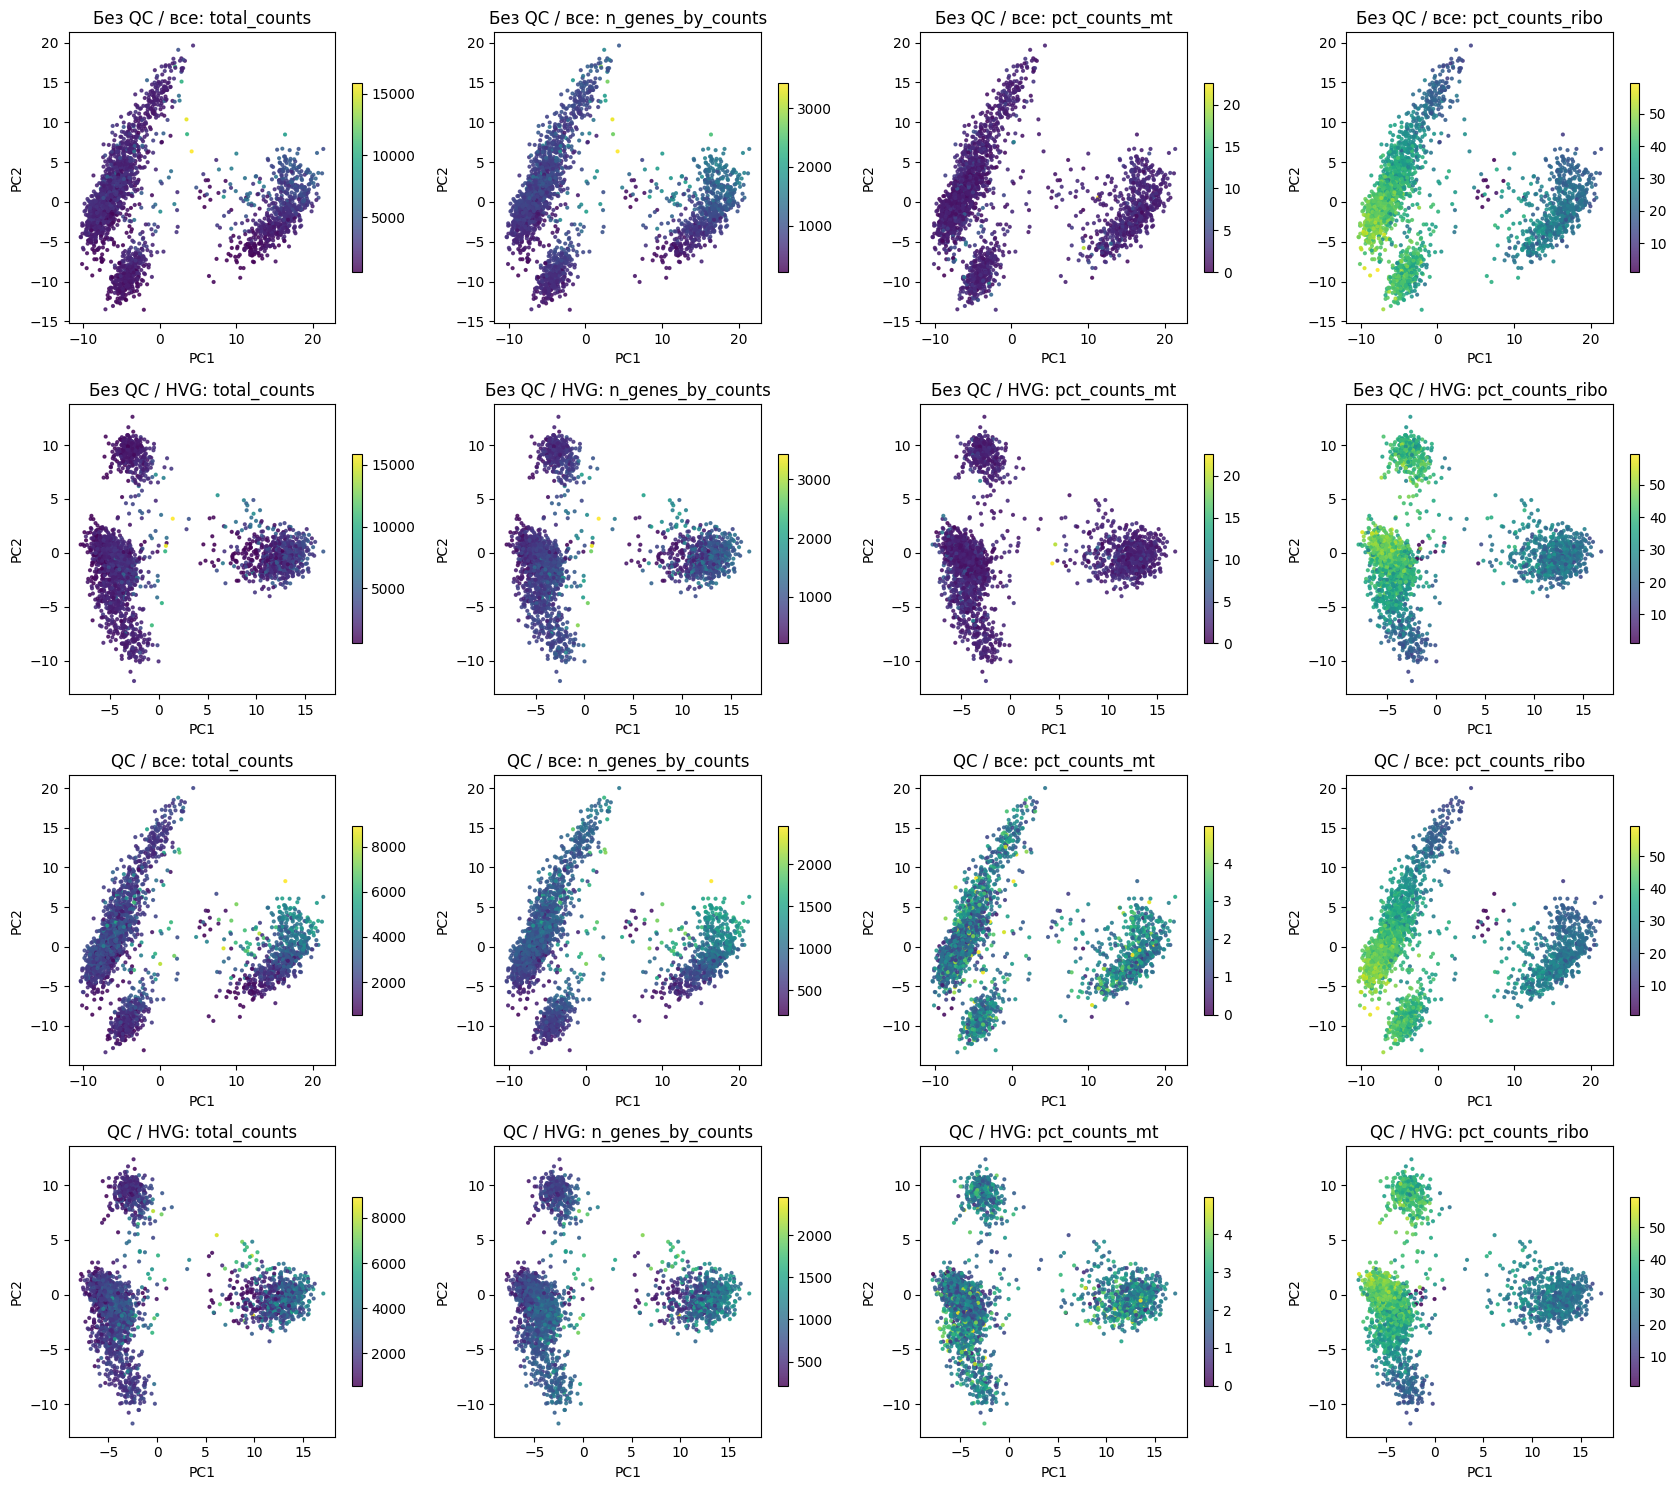

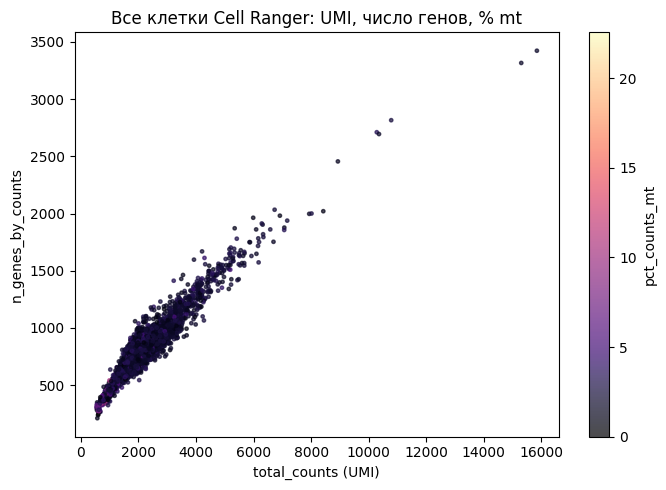

In [33]:
unfiltered_norm = raw.copy()
sc.pp.normalize_total(unfiltered_norm, target_sum=1e4)
sc.pp.log1p(unfiltered_norm)
unfiltered_hvg = sc.pp.highly_variable_genes(raw, layer="counts", flavor="seurat_v3",
                                              n_top_genes=2000, inplace=False)
mask_unfiltered = unfiltered_hvg["highly_variable"].reindex(raw.var_names).fillna(False).to_numpy()
case1 = pca_copy(unfiltered_norm)               # без QC, все гены
case2 = pca_copy(unfiltered_norm, mask_unfiltered) # без QC, HVG
case3 = pca_all                                # QC, все гены
case4 = pcas["seurat_v3"]                     # QC, HVG
CASES = [case1, case2, case3, case4]
CASE_LABELS = ["Без QC / все", "Без QC / HVG", "QC / все", "QC / HVG"]
COLORS = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]

fig, axes = plt.subplots(4, 4, figsize=(17, 15))
for i, (obj, label) in enumerate(zip(CASES, CASE_LABELS)):
    for j, field in enumerate(COLORS):
        ax = axes[i, j]
        im = ax.scatter(obj.obsm["X_pca"][:, 0], obj.obsm["X_pca"][:, 1],
                        c=obj.obs[field], s=4, alpha=.8, cmap="viridis", rasterized=True)
        ax.set(xlabel="PC1", ylabel="PC2", title=f"{label}: {field}")
        fig.colorbar(im, ax=ax, shrink=.65)
finish_figure("task5_four_scenarios.png")

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.scatter(raw.obs["total_counts"], raw.obs["n_genes_by_counts"],
                c=raw.obs["pct_counts_mt"], s=6, cmap="magma", alpha=.7, rasterized=True)
ax.set(xlabel="total_counts (UMI)", ylabel="n_genes_by_counts",
       title="Все клетки Cell Ranger: UMI, число генов, % mt")
fig.colorbar(im, ax=ax, label="pct_counts_mt")
finish_figure("task5_counts_genes_mt.png")

По графикам видно, что положение клеток частично связано с количеством UMI, где выше тотал каунтс, там обычно больше и обнаруженных генов. На диаграмме эти показатели почти линейно связаны. Для доли митохондриальных транскриптов чёткого направления нет, но до QC видны отдельные клетки с высокими значениями. можно сделать вывод, что технические факторы влияют на PCA, но после QC и выбора HVG это влияние становится слабее


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

,gene,loading,PC,direction
0,LTB,-0.112827,1,negative
1,IL32,-0.106144,1,negative
2,MALAT1,-0.067260,1,negative
3,IL7R,-0.059417,1,negative
4,CCL5,-0.051053,1,negative
5,CD2,-0.045544,1,negative
6,CTSW,-0.043735,1,negative
7,STK17A,-0.037906,1,negative
8,ACAP1,-0.036313,1,negative
9,CD247,-0.036139,1,negative


,gene,loading,PC,direction
0,NKG7,-0.216003,2,negative
1,S100A4,-0.180782,2,negative
2,CCL5,-0.165346,2,negative
3,IL32,-0.144603,2,negative
4,GNLY,-0.134453,2,negative
5,CTSW,-0.134233,2,negative
6,GZMA,-0.134096,2,negative
7,CST7,-0.131238,2,negative
8,SRGN,-0.123198,2,negative
9,ANXA1,-0.120073,2,negative


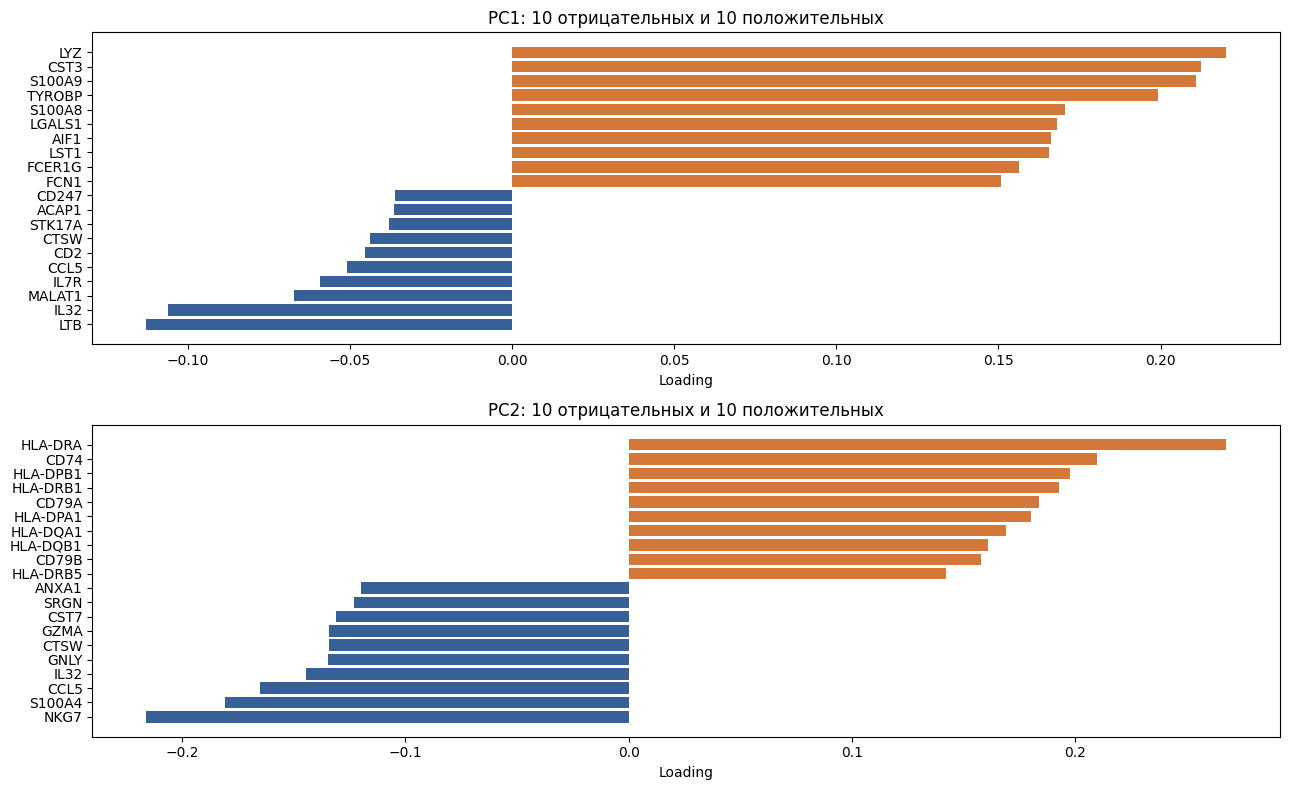

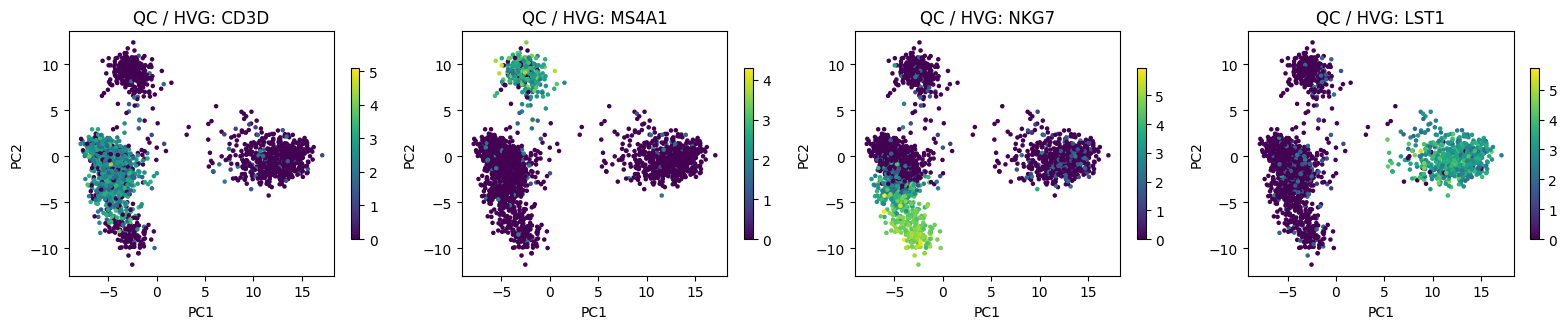

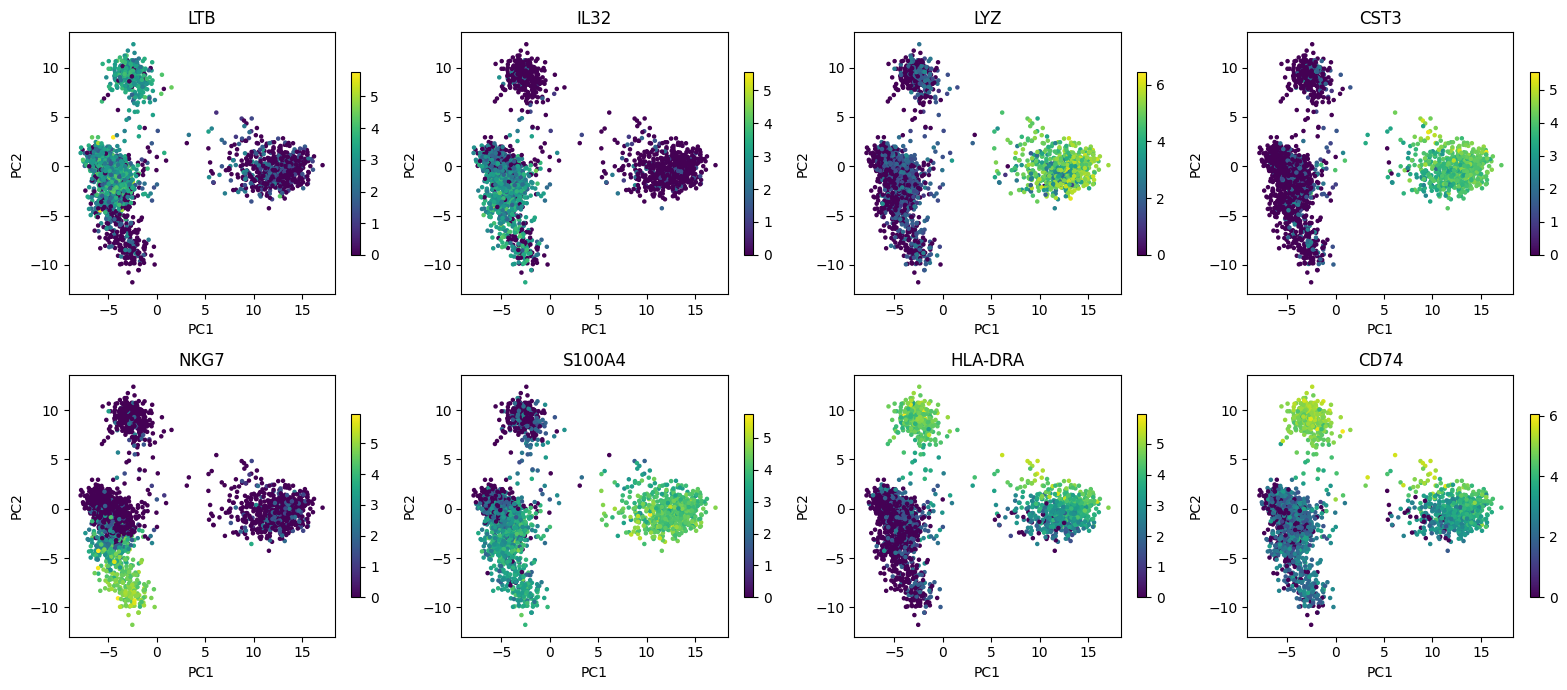

In [34]:
pca_v3 = pcas["seurat_v3"]
loading_matrix = pca_v3.varm["PCs"]
selected = np.asarray(hvg["seurat_v3"], dtype=bool)
gene_names = pca_v3.var_names.to_numpy()[selected]
if loading_matrix.shape[0] == pca_v3.n_vars:
    loadings = loading_matrix[selected, :2]
elif loading_matrix.shape[0] == selected.sum():
    loadings = loading_matrix[:, :2]
else:
    raise ValueError("Неожиданное число строк в матрице нагрузок PCA")
top_by_pc = {}
for component in range(2):
    order = np.argsort(loadings[:, component])
    negative = pd.DataFrame({"gene": gene_names[order[:10]],
                             "loading": loadings[order[:10], component], "PC": component + 1})
    positive = pd.DataFrame({"gene": gene_names[order[-10:][::-1]],
                             "loading": loadings[order[-10:][::-1], component], "PC": component + 1})
    top_by_pc[component + 1] = (negative, positive)
    display(pd.concat([negative.assign(direction="negative"),
                       positive.assign(direction="positive")], ignore_index=True))
pd.concat([part.assign(direction=direction) for parts in top_by_pc.values()
           for part, direction in zip(parts, ["negative", "positive"])],
          ignore_index=True).to_csv(OUT / "task6_loadings_top10.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for ax, pc in zip(axes, (1, 2)):
    neg, pos = top_by_pc[pc]
    values = pd.concat([neg, pos]).sort_values("loading")
    ax.barh(values["gene"], values["loading"],
            color=["#375f98" if x < 0 else "#d47839" for x in values["loading"]])
    ax.set(xlabel="Loading", title=f"PC{pc}: 10 отрицательных и 10 положительных")
finish_figure("task6_loadings.png")

selected_genes = list(dict.fromkeys(
    [g for pc in (1, 2) for part in top_by_pc[pc] for g in part.head(2)["gene"]]
))
plot_marker_comparison([pca_v3], ["QC / HVG"], "task6_reference_marker_pca.png")
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, gene in zip(axes.ravel(), selected_genes):
    im = ax.scatter(pca_v3.obsm["X_pca"][:, 0], pca_v3.obsm["X_pca"][:, 1],
                    c=gene_values(norm, gene), s=5, cmap="viridis", rasterized=True)
    ax.set(xlabel="PC1", ylabel="PC2", title=gene)
    fig.colorbar(im, ax=ax, shrink=.7)
for ax in axes.ravel()[len(selected_genes):]:
    ax.axis("off")
finish_figure("task6_genes_on_pca.png")

По графикам видно, что PC1 в основном разделяет моноциты и T-клетки. Положительные значения связаны с генами LYZ, CST3, S100A8, S100A9 и LST1, а отрицательные с LTB, IL32, IL7R и CD2. PC2 разделяет B-клетки с генами CD74, CD79A и HLA-DRA и NK-клетки с NKG7, GNLY и CCL5. Стоит отметить, что очевидной связи с клеточным циклом или QC-метриками нет

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток.

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

In [35]:
from scipy.stats import spearmanr

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


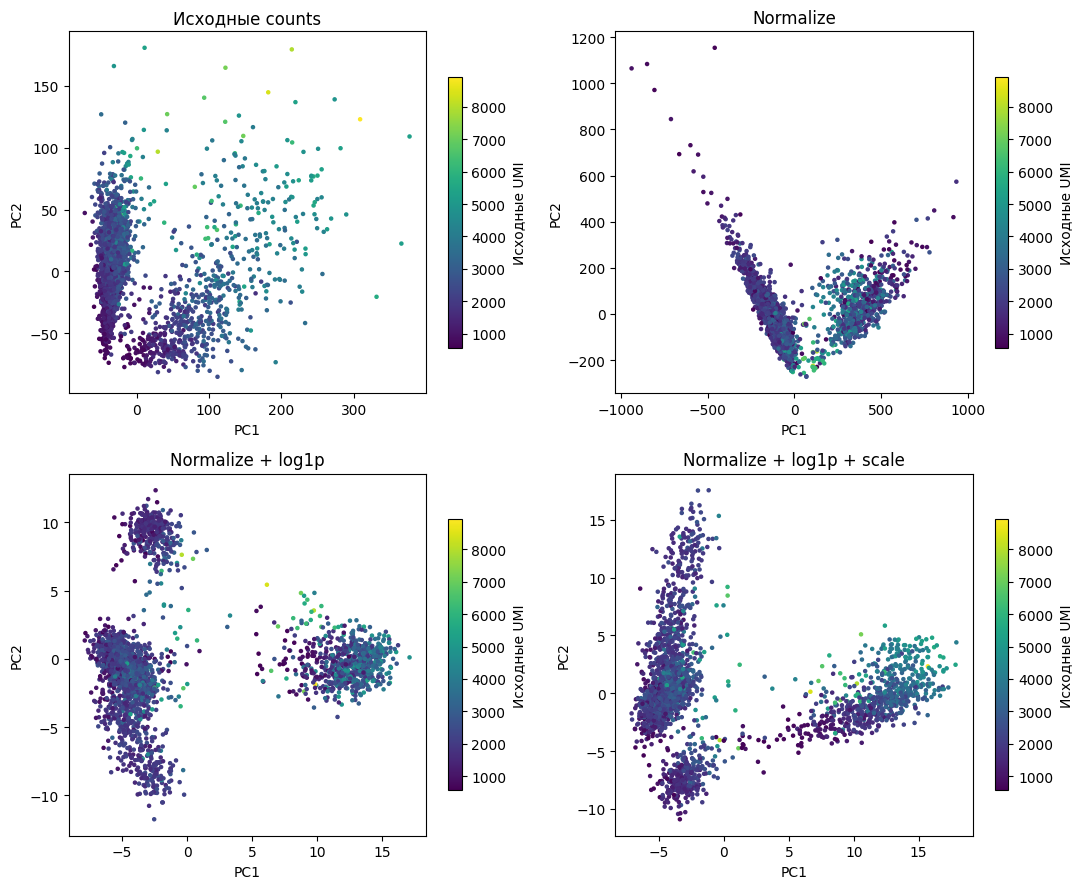

,variant,PC1_variance,PC2_variance,abs_spearman_PC1_total_counts
0,Исходные counts,0.440563,0.143095,0.490150
1,Normalize,0.393943,0.109267,0.268119
2,Normalize + log1p,0.099776,0.032816,0.242641
3,Normalize + log1p + scale,0.029061,0.011657,0.291013


In [36]:
def preprocessing_variant(name, normalize=False, log=False, scale=False):
    obj = filtered.copy()
    if normalize:
        sc.pp.normalize_total(obj, target_sum=1e4)
    if log:
        sc.pp.log1p(obj)
    obj = obj[:, hvg["seurat_v3"]].copy()
    if scale:
        sc.pp.scale(obj, max_value=10)
    sc.pp.pca(obj, n_comps=30, svd_solver="arpack", random_state=0)
    return obj

variants = {
    "Исходные counts": preprocessing_variant("counts"),
    "Normalize": preprocessing_variant("normalize", normalize=True),
    "Normalize + log1p": preprocessing_variant("log", normalize=True, log=True),
    "Normalize + log1p + scale": preprocessing_variant("scale", normalize=True, log=True, scale=True),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
summary = []
for ax, (name, obj) in zip(axes.ravel(), variants.items()):
    im = ax.scatter(obj.obsm["X_pca"][:, 0], obj.obsm["X_pca"][:, 1],
                    c=obj.obs["total_counts"], s=5, cmap="viridis", rasterized=True)
    ax.set(xlabel="PC1", ylabel="PC2", title=name)
    fig.colorbar(im, ax=ax, label="Исходные UMI", shrink=.75)
    ratio = obj.uns["pca"]["variance_ratio"]
    rho = spearmanr(obj.obsm["X_pca"][:, 0], obj.obs["total_counts"]).statistic
    summary.append({"variant": name, "PC1_variance": ratio[0], "PC2_variance": ratio[1],
                    "abs_spearman_PC1_total_counts": abs(rho)})
finish_figure("task7_preprocessing_pca.png")
display(pd.DataFrame(summary))
pd.DataFrame(summary).to_csv(OUT / "task7_summary.csv", index=False)

Сильнее всего на PCA повлияло логарифмирование, тк после лог1п группы клеток стали намного лучше разделяться, и влияние больших значений уменьшилось. Нормализация  снижает зависимость от общего количества UMI, корреляция с PC1 уменьшилась с 0,49 до 0,27. скейл заметно изменил форму графика, но сильного улучшения не дал. Получается, что нормализация выравнивает клетки по общему числу UMI, логарифмирование уменьшает влияние очень высокой экспрессии, а скейл приводит гены к одному масштабу. Перед PCA нормализация и лог1п нужны, а скейл можно использовать не всегда.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?